
# Figure 1b — Monte-Carlo Parameter Priors

Four-panel figure illustrating the observation-informed priors used in the Monte-Carlo retrieval-error estimation (notebooks 07–08).

Output: `outputs/figures/fig01b_mc_parameter_overview.png`


In [1]:
%cd ..
from __future__ import annotations

import glob
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde
import shapely

from src.data_helpers import load_aer_ai, load_aer_lh, get_modis_hotspot
from src.wind_helpers import match_alh_plume_pressures
from src import error_estimation as ee
from src import plume_helpers as ph

PROJECT_ROOT = Path(".").resolve()
print(f"Project root: {PROJECT_ROOT}")

/Users/maperezc/Downloads/wildfires
Project root: /Users/maperezc/Downloads/wildfires


In [2]:
# ── Paths & constants ──────────────────────────────────────────────────────
FIRE_DATE  = "2026-01-18"
TARGET_DAY = "0118"
DATA_DIR   = PROJECT_ROOT / "data"
OUT_DIR    = PROJECT_ROOT / "outputs" / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)

AER_AI_L2_PATH = [sorted(glob.glob(str(DATA_DIR / TARGET_DAY / "S5P_OFFL_L2__AER_AI_2026*")))[0]]
AER_LH_L2_PATH = sorted(glob.glob(str(DATA_DIR / TARGET_DAY / "S5P_OFFL_L2__AER_LH_2026*")))
ERA5_PL_PATH   = DATA_DIR / "ERA5_winds_pressure_levels.nc"
HOTSPOT_CSV    = DATA_DIR / "daily_dominant_hotspot_summary.csv"
MODIS_CSV      = DATA_DIR / "fire_nrt_M-C61_723973.csv"

# Plume boundary saved by notebooks/plume_boundary_inspection.ipynb — carries
# both the AI threshold and the blob-clustered inclusion geometry for this date.
PLUME_BOUNDARY_PATH = DATA_DIR / TARGET_DAY / "plume_boundary.geojson"

LAT_MIN, LAT_MAX = -40.0, -28.0
LON_MIN, LON_MAX = -80.0, -68.0

PRESS_RADIUS_KM   = 450.0
PRESS_MIN_PIXELS  = 15
QA_UINT8          = 50

# Centroid KDE parameters (match nb07/08)
CENTROID_LOCAL_RADIUS_KM = 200.0
CENTROID_MIN_CONF        = 75
CENTROID_SAT             = "Aqua"
CENTROID_DAYNIGHT        = "D"

print("Constants loaded.")

Constants loaded.


In [3]:
# ── Load TROPOMI products (all overpasses, concatenated) ──────────────────
def load_and_concat(paths, loader, **kwargs):
    chunks = defaultdict(list)
    scalars = {}
    for pth in paths:
        pth = Path(pth)
        data = loader(pth, **kwargs)
        if data is None:
            continue  # skip orbits with no valid pixels in the ROI
        for k, v in data.items():
            if isinstance(v, np.ndarray):
                chunks[k].append(v)
            else:
                scalars[k] = v
    out = {k: np.concatenate(v) for k, v in chunks.items()}
    out.update(scalars)
    return out


roi_kwargs = dict(
    lat_min=LAT_MIN, lat_max=LAT_MAX,
    lon_min=LON_MIN, lon_max=LON_MAX,
    qa_threshold=QA_UINT8,
)
ai_data  = load_and_concat(AER_AI_L2_PATH, load_aer_ai, **roi_kwargs)
alh_data = load_and_concat(AER_LH_L2_PATH, load_aer_lh, **roi_kwargs)

modis    = get_modis_hotspot(HOTSPOT_CSV, FIRE_DATE,
                              lat_min=LAT_MIN, lat_max=LAT_MAX,
                              lon_min=LON_MIN, lon_max=LON_MAX)
FIRE_LAT = float(modis["dominant_lat"].values[0])
FIRE_LON = float(modis["dominant_lon"].values[0])

# ── Plume boundary: clip AI outside the saved blob-clustered inclusion
# geometry down below threshold, replacing the previous ad hoc "lon > -72"
# clip. AI_THRESHOLD is read from the boundary file, not hardcoded.
plume_boundary = ph.load_plume_boundary(PLUME_BOUNDARY_PATH)
AI_THRESHOLD = plume_boundary.threshold
_in_boundary = shapely.contains_xy(plume_boundary.boundary, ai_data["lon"], ai_data["lat"])
ai_vals = np.where(_in_boundary, ai_data["ai"], np.minimum(ai_data["ai"], AI_THRESHOLD - 1e-3))
print(f"Plume boundary: {plume_boundary.boundary.geom_type}  threshold={AI_THRESHOLD:.3f}  "
      f"({int(_in_boundary.sum())}/{_in_boundary.size} AER_AI pixels inside boundary)")

print(f"Fire centroid: ({FIRE_LAT:.4f}, {FIRE_LON:.4f})")
print(f"AER_AI pixels: {len(ai_vals):,}")
print(f"AER_LH pixels: {len(alh_data['alh_pres']):,}")

Plume boundary: MultiPolygon  threshold=2.000  (2561/39625 AER_AI pixels inside boundary)
Fire centroid: (-37.5484, -72.5545)
AER_AI pixels: 39,625
AER_LH pixels: 8,206


In [4]:
# ── Injection-pressure KDE ─────────────────────────────────────────────────
pk = ee.build_pressure_kde(
    ai_vals, ai_data["lat"], ai_data["lon"],
    alh_data["alh_pres"], alh_data["lat"], alh_data["lon"],
    FIRE_LAT, FIRE_LON,
    ai_threshold=AI_THRESHOLD,
    radius_km=PRESS_RADIUS_KM,
    min_pixels=PRESS_MIN_PIXELS,
)
pres_hpa   = pk["samples_hpa"]           # matched pressures
pres_kde   = pk["kde"]                   # scipy gaussian_kde
pres_med   = pk["median_hpa"]
pres_mean   = pk["mean_hpa"]
pres_iqr   = pk["iqr_hpa"]
pres_q25, pres_q75 = np.percentile(pres_hpa, [25, 75])

print(f"Matched pixels: {pk['n']}")
print(f"Mean pressure: {pres_mean:.0f} hPa  IQR: {pres_iqr:.0f} hPa")

Matched pixels: 99
Mean pressure: 882 hPa  IQR: 73 hPa


In [5]:
# ── Centroid KDE ───────────────────────────────────────────────────────────
ck = ee.build_centroid_kde(
    MODIS_CSV, FIRE_DATE, FIRE_LAT, FIRE_LON,
    local_radius_km=CENTROID_LOCAL_RADIUS_KM,
    min_confidence=CENTROID_MIN_CONF,
    satellite=CENTROID_SAT,
    daynight=CENTROID_DAYNIGHT,
)
modis_lats = ck["lats"]
modis_lons = ck["lons"]
modis_frp  = ck["frp"]

# Evaluate KDE on a grid for contours
lon_grid_c = np.linspace(modis_lons.min() - 0.3, modis_lons.max() + 0.3, 120)
lat_grid_c = np.linspace(modis_lats.min() - 0.3, modis_lats.max() + 0.3, 120)
LON_CG, LAT_CG = np.meshgrid(lon_grid_c, lat_grid_c)
kde_vals = ck["kde"](np.vstack([LAT_CG.ravel(), LON_CG.ravel()])).reshape(LAT_CG.shape)

# Recenter shift (same as nb07/08 to show recentered mean)
_cs = ck["kde"].resample(5000, seed=42)
kde_mean_lat = float(_cs[0].mean())
kde_mean_lon = float(_cs[1].mean())

print(f"MODIS detections: {ck['n']}")
print(f"KDE mean: ({kde_mean_lat:.4f}, {kde_mean_lon:.4f})")
print(f"Recentered on fire: ({FIRE_LAT:.4f}, {FIRE_LON:.4f})")

MODIS detections: 146
KDE mean: (-37.0570, -72.7503)
Recentered on fire: (-37.5484, -72.5545)


In [6]:
# ── ERA5 wind profile at fire location ────────────────────────────────────
era5     = xr.open_dataset(ERA5_PL_PATH)
time_dim = "valid_time" if "valid_time" in era5.dims else "time"
era5_t   = era5.sel({time_dim: pd.Timestamp("2026-01-18 18:00")}, method="nearest")

lat_key = "latitude" if "latitude" in era5_t.coords else "lat"
lon_key = "longitude" if "longitude" in era5_t.coords else "lon"
era5_lats = era5_t[lat_key].values
era5_lons = era5_t[lon_key].values

i_lat = int(np.argmin(np.abs(era5_lats - FIRE_LAT)))
i_lon = int(np.argmin(np.abs(era5_lons - FIRE_LON)))

p_levels  = era5_t["pressure_level"].values.ravel()   # hPa
u_profile = era5_t["u"].isel(**{lat_key: i_lat, lon_key: i_lon}).values.ravel()
v_profile = era5_t["v"].isel(**{lat_key: i_lat, lon_key: i_lon}).values.ravel()
spd_profile = np.hypot(u_profile, v_profile)
dir_profile = np.degrees(np.arctan2(v_profile, u_profile))  # CCW from east

# Sort by pressure ascending for plotting
sort_idx   = np.argsort(p_levels)
p_sorted   = p_levels[sort_idx]
u_sorted   = u_profile[sort_idx]
v_sorted   = v_profile[sort_idx]
spd_sorted = spd_profile[sort_idx]
dir_sorted = dir_profile[sort_idx]

# Draw 500 pressure samples from the KDE to show the sampled wind range
p_lo, p_hi = float(p_sorted.min()), float(p_sorted.max())
rng = np.random.default_rng(42)
p_samples_raw = pres_kde.resample(500, seed=42).flatten()
p_samples     = np.clip(p_samples_raw, p_lo, p_hi)
log_p         = np.log(p_sorted)
spd_samples   = np.array([float(np.interp(np.log(p), log_p, spd_sorted)) for p in p_samples])
dir_samples   = np.array([float(np.interp(np.log(p), log_p, dir_sorted)) for p in p_samples])
u_samples     = np.array([float(np.interp(np.log(p), log_p, u_sorted)) for p in p_samples])
v_samples     = np.array([float(np.interp(np.log(p), log_p, v_sorted)) for p in p_samples])

print(f"ERA5 pressure levels available: {p_sorted}")
print(f"Sampled wind speed: median={np.median(spd_samples):.2f} m/s  "
      f"[{np.percentile(spd_samples, 2.5):.2f}, {np.percentile(spd_samples, 97.5):.2f}]")

ERA5 pressure levels available: [125. 175. 225. 300. 400. 500. 600. 700. 775. 825. 875. 925. 975.]
Sampled wind speed: median=9.38 m/s  [1.48, 10.61]


In [7]:
# ── AER_LH pixels: identify matched vs unmatched within radius ────────────
# For panel b: show all AER_LH pixels coloured by their plume-match status
from src.wind_helpers import _haversine_km

alh_lat  = alh_data["lat"]
alh_lon  = alh_data["lon"]
alh_pres = alh_data["alh_pres"]

# Haversine distance from fire centroid to each AER_LH pixel
dist_alh = _haversine_km(FIRE_LAT, FIRE_LON, alh_lat, alh_lon)

# Within radius and finite
in_radius = (dist_alh <= PRESS_RADIUS_KM) & np.isfinite(alh_pres) & (alh_pres > 0)

# These are the matched pressures in hPa (same logic as match_alh_plume_pressures)
# but we want to show ALL in-radius pixels coloured by match status
matched_result = match_alh_plume_pressures(
    ai_vals, ai_data["lat"], ai_data["lon"],
    alh_data["alh_pres"], alh_data["lat"], alh_data["lon"],
    FIRE_LAT, FIRE_LON,
    ai_threshold=AI_THRESHOLD,
    radius_km=PRESS_RADIUS_KM,
)
# We need to identify which in-radius pixels were matched to the plume
# Rebuild the match mask to colour pixels on the map
from scipy.spatial import cKDTree
from src.wind_helpers import _latlon_to_xyz

plume_mask = (ai_vals > AI_THRESHOLD) & np.isfinite(ai_vals)
in_radius_idx = np.where(in_radius)[0]

if in_radius_idx.size > 0:
    tree = cKDTree(_latlon_to_xyz(ai_data["lat"], ai_data["lon"]))
    _, nn_idx = tree.query(
        _latlon_to_xyz(alh_lat[in_radius], alh_lon[in_radius]), k=1, workers=-1
    )
    in_plume_mask = plume_mask[nn_idx]  # True if nearest AI pixel is in plume
else:
    in_plume_mask = np.array([], dtype=bool)

# Coordinates for plotting
alh_in_lat     = alh_lat[in_radius]
alh_in_lon     = alh_lon[in_radius]
alh_in_pres    = alh_pres[in_radius] / 100.0   # Pa -> hPa

print(f"AER_LH within {PRESS_RADIUS_KM:.0f} km: {in_radius.sum()}")
print(f"  matched to plume: {in_plume_mask.sum()}")
print(f"  not matched (outside plume): {(~in_plume_mask).sum()}")

AER_LH within 450 km: 6543
  matched to plume: 99
  not matched (outside plume): 6444


In [8]:

# ── Wind-aligned AER_AI frame + plume PCA axis (for panel d) ──────────────
# Injection pressure and wind (median of the KDE, matching the canonical retrieval)
log_p    = np.log(p_sorted)
U_WIND   = float(np.interp(np.log(pres_mean), log_p, u_sorted))
V_WIND   = float(np.interp(np.log(pres_mean), log_p, v_sorted))
WIND_SPD = float(np.hypot(U_WIND, V_WIND))
THETA    = float(np.arctan2(V_WIND, U_WIND))   # radians, CCW from east

# Rotate all AER_AI pixels into the wind-aligned frame
M_PER_DEG_LON = 111_320.0 * np.cos(np.deg2rad(FIRE_LAT))
x_km = (ai_data["lon"] - FIRE_LON) * M_PER_DEG_LON / 1000.0
y_km = (ai_data["lat"] - FIRE_LAT) * 111_320.0        / 1000.0
cos_t, sin_t = np.cos(THETA), np.sin(THETA)
x_rot =  x_km * cos_t + y_km * sin_t   # downwind  (+x = wind direction)
y_rot = -x_km * sin_t + y_km * cos_t   # cross-wind

# Bin onto regular km grid
GRID_KM = 8.0
X_MIN_D, X_MAX_D = -100.0, 800.0
Y_MIN_D, Y_MAX_D = -300.0,  300.0
x_edges   = np.arange(X_MIN_D, X_MAX_D + 1e-9, GRID_KM)
y_edges   = np.arange(Y_MIN_D, Y_MAX_D + 1e-9, GRID_KM)
x_centres = 0.5 * (x_edges[:-1] + x_edges[1:])
y_centres = 0.5 * (y_edges[:-1] + y_edges[1:])
nx_g, ny_g = len(x_centres), len(y_centres)

ix = np.digitize(x_rot, x_edges) - 1
iy = np.digitize(y_rot, y_edges) - 1
ok = (ix >= 0) & (ix < nx_g) & (iy >= 0) & (iy < ny_g)
grid_sum = np.zeros((nx_g, ny_g))
grid_cnt = np.zeros((nx_g, ny_g), dtype=int)
np.add.at(grid_sum, (ix[ok], iy[ok]), ai_vals[ok])
np.add.at(grid_cnt, (ix[ok], iy[ok]), 1)
ai_grid = np.where(grid_cnt > 0, grid_sum / grid_cnt, np.nan)

# ── Plume PCA axis ─────────────────────────────────────────────────────────
# AI-weighted PCA of plume pixels within PCA_RADIUS_KM of the fire centroid.
# Mirrors the alignment gate in nb08.  Returns theta_plume (CCW from east, rad).
PCA_RADIUS_KM   = 450.0
FAR_FIELD_MIN_KM = 150.0

plume_px = ai_vals > AI_THRESHOLD
_dist_pca = np.sqrt(x_km**2 + y_km**2)   # rough distance in km (flat-Earth fine here)
within = plume_px & (_dist_pca <= PCA_RADIUS_KM)

_w   = ai_vals[within]
_W   = _w / _w.sum()
_xw  = x_km[within]; _yw = y_km[within]
_xc  = float(_W @ _xw); _yc = float(_W @ _yw)
_dx  = _xw - _xc;  _dy = _yw - _yc
_cov = np.array([[_W @ (_dx * _dx), _W @ (_dx * _dy)],
                  [_W @ (_dx * _dy), _W @ (_dy * _dy)]])
_, _evecs = np.linalg.eigh(_cov)
_axis = _evecs[:, -1].copy()

# Resolve sign: point toward the far-field plume mass
_r   = np.sqrt(_xw**2 + _yw**2)
_far = _r > FAR_FIELD_MIN_KM
_xff = float(np.average(_xw[_far], weights=_w[_far]))
_yff = float(np.average(_yw[_far], weights=_w[_far]))
if _axis[0] * _xff + _axis[1] * _yff < 0:
    _axis = -_axis

# θ_plume in geographic (lat/lon) space, then relative to wind frame
THETA_PLUME_GEO = float(np.arctan2(_axis[1], _axis[0]))   # CCW from east (geo)
# Angle of the plume axis *relative to the wind direction* in the rotated frame
DELTA_THETA_DEG = float(np.degrees(THETA_PLUME_GEO - THETA))
# Keep in [-180, 180]
DELTA_THETA_DEG = ((DELTA_THETA_DEG + 180) % 360) - 180
# Ensure it points into the downwind half
if abs(DELTA_THETA_DEG) > 90:
    DELTA_THETA_DEG = DELTA_THETA_DEG - np.sign(DELTA_THETA_DEG) * 180

print(f"ERA5 at {pres_mean:.0f} hPa: U={U_WIND:+.2f} m/s  V={V_WIND:+.2f} m/s  speed={WIND_SPD:.2f} m/s")
print(f"Wind direction (geo):  {np.degrees(THETA):.1f}° (CCW from east)")
print(f"Plume PCA direction:   {np.degrees(THETA_PLUME_GEO):.1f}°")
print(f"Δθ (plume vs wind):    {DELTA_THETA_DEG:.1f}°  (gate: ±15°)")
print(f"Grid: {nx_g}×{ny_g} cells at {GRID_KM} km resolution")


ERA5 at 882 hPa: U=-4.78 m/s  V=+7.29 m/s  speed=8.72 m/s
Wind direction (geo):  123.3° (CCW from east)
Plume PCA direction:   114.7°
Δθ (plume vs wind):    -8.6°  (gate: ±15°)
Grid: 112×75 cells at 8.0 km resolution


/var/folders/0j/71sn2s2j71l6q088k8_ppzsc0000gn/T/ipykernel_92702/2221334569.py:34: RuntimeWarning: invalid value encountered in divide
  ai_grid = np.where(grid_cnt > 0, grid_sum / grid_cnt, np.nan)


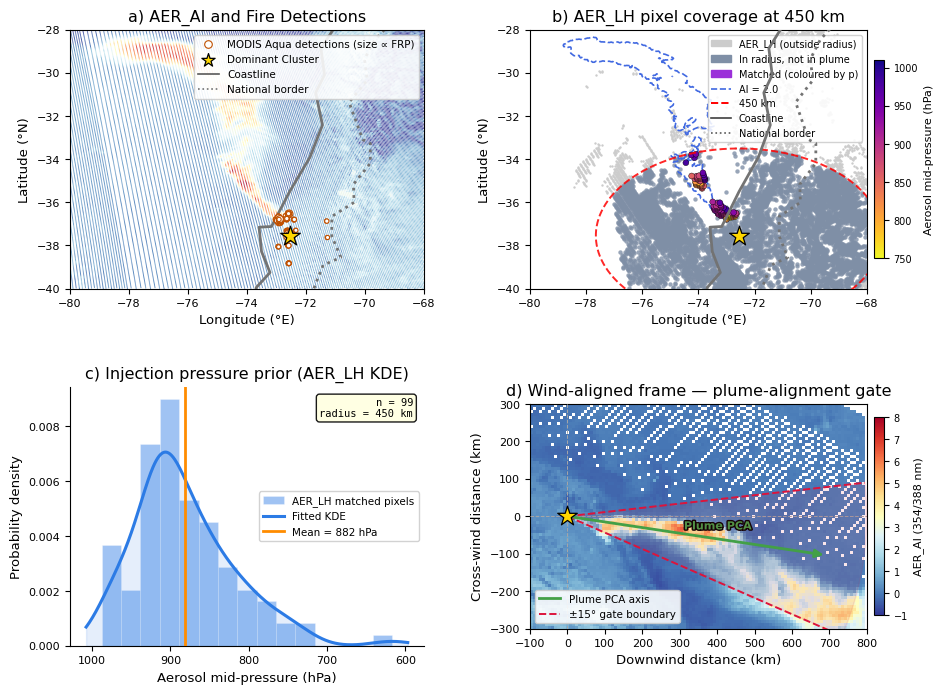


Saved: /Users/maperezc/Downloads/wildfires/outputs/figures/fig01b_mc_parameter_overview.png


In [9]:
import matplotlib.patheffects as pe
import cartopy.io.shapereader as shpreader
from shapely.geometry import box as shapely_box


# ── Load Natural Earth 110m coastline + borders (for panels a & b) ────────
_land_shp = shpreader.natural_earth(resolution="110m", category="physical", name="land")
_land_geoms = list(shpreader.Reader(_land_shp).geometries())

_border_shp = shpreader.natural_earth(resolution="110m", category="cultural",
                                       name="admin_0_boundary_lines_land")
_border_geoms = list(shpreader.Reader(_border_shp).geometries())

_domain_box = shapely_box(LON_MIN, LAT_MIN, LON_MAX, LAT_MAX)

def _draw_coastline_and_borders(ax, coast_color="0.45", border_color="0.45",
                                 coast_lw=2.0, border_lw=2.0, zorder=2):
    for geom in _land_geoms:
        if not geom.intersects(_domain_box):
            continue
        polys = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]
        for poly in polys:
            xc, yc = poly.exterior.xy
            ax.plot(xc, yc, color=coast_color, lw=coast_lw, zorder=zorder)
    for geom in _border_geoms:
        if not geom.intersects(_domain_box):
            continue
        lines = list(geom.geoms) if geom.geom_type == "MultiLineString" else [geom]
        for line in lines:
            xb, yb = line.xy
            ax.plot(xb, yb, color=border_color, lw=border_lw, ls=":", zorder=zorder)


# ── 2×2 figure ─────────────────────────────────────────────────────────────
FIRE_KW = dict(marker="*", s=220, c="gold", edgecolors="black",
               linewidths=0.9, zorder=8)
FIRE_LEGEND_KW = dict(marker="*", s=100, c="gold", edgecolors="black", linewidths=0.9)

COLOR_NOMATCH = "#7f8fa6"
COLOR_KDE     = "#2c7be5"
COLOR_MED     = "darkorange"
AI_VMIN, AI_VMAX = -1.0, 8.0

fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0),
                          gridspec_kw={"hspace": 0.38, "wspace": 0.30})
(ax_a, ax_b), (ax_c, ax_d) = axes


# ━━ a) Fire Detections ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ax_a.scatter(ai_data["lon"], ai_data["lat"], c=ai_vals,
              cmap="RdYlBu_r", vmin=-1, vmax=6, s=0.6,
              linewidths=0, rasterized=True, alpha=1.0, zorder=1)

_draw_coastline_and_borders(ax_a)

frp_norm = modis_frp / modis_frp.max()
ax_a.scatter(modis_lons, modis_lats, s=frp_norm * 60 + 8,
              c="white", edgecolors="#c05000", linewidths=0.8, zorder=5)
ax_a.scatter(FIRE_LON, FIRE_LAT, **FIRE_KW)

ax_a.set_xlim(LON_MIN, LON_MAX);  ax_a.set_ylim(LAT_MIN, LAT_MAX)
ax_a.set_xlabel("Longitude (°E)", fontsize=9.5)
ax_a.set_ylabel("Latitude (°N)", fontsize=9.5)
ax_a.tick_params(labelsize=8)
ax_a.legend(fontsize=7.5, loc="upper right", framealpha=0.88,
             handles=[
                 ax_a.scatter([], [], s=30, c="white", edgecolors="#c05000",
                              lw=0.8, label="MODIS Aqua detections (size ∝ FRP)"),
                 ax_a.scatter([], [], **FIRE_LEGEND_KW, label="Dominant Cluster"),
                 Line2D([0], [0], color="0.35", lw=1.2, label="Coastline"),
                 Line2D([0], [0], color="0.45", lw=1.2, ls=":", label="National border"),
             ])
ax_a.set_title("a) AER_AI and Fire Detections", fontsize=11.5)


# ━━ b) AER_LH pixel coverage ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
out_radius = ~in_radius
ax_b.scatter(alh_lon[out_radius], alh_lat[out_radius],
              s=3, c="0.80", linewidths=0, rasterized=True, zorder=1)
ax_b.scatter(alh_in_lon[~in_plume_mask], alh_in_lat[~in_plume_mask],
              s=10, c=COLOR_NOMATCH, linewidths=0, rasterized=True, zorder=2, alpha=0.8)
sc_b = ax_b.scatter(
    alh_in_lon[in_plume_mask], alh_in_lat[in_plume_mask],
    c=alh_in_pres[in_plume_mask], cmap="plasma_r", vmin=750, vmax=1010,
    s=18, linewidths=0.3, edgecolors="k", rasterized=True, zorder=4,
)

_draw_coastline_and_borders(ax_b, zorder=6)

theta_c = np.linspace(0, 2 * np.pi, 720)
km_per_deg_lat = 111.32
km_per_deg_lon = 111.32 * np.cos(np.deg2rad(FIRE_LAT))
ax_b.plot(FIRE_LON + (PRESS_RADIUS_KM / km_per_deg_lon) * np.cos(theta_c),
           FIRE_LAT + (PRESS_RADIUS_KM / km_per_deg_lat) * np.sin(theta_c),
           "r--", lw=1.4, alpha=0.85, zorder=5)
from scipy.spatial import cKDTree as _CKD
N_R = 200
lon_r = np.linspace(LON_MIN, LON_MAX, N_R)
lat_r = np.linspace(LAT_MIN, LAT_MAX, N_R)
LG, LaG = np.meshgrid(lon_r, lat_r)
tree_ai  = _CKD(np.column_stack([ai_data["lat"], ai_data["lon"]]))
_, nn = tree_ai.query(np.column_stack([LaG.ravel(), LG.ravel()]), k=1, workers=-1)
AI_Gr = ai_vals[nn].reshape(N_R, N_R)
ax_b.contour(LG, LaG, AI_Gr, levels=[AI_THRESHOLD],
              colors=["royalblue"], linewidths=[1.2], linestyles=["--"], zorder=3)
ax_b.scatter(FIRE_LON, FIRE_LAT, **FIRE_KW)
cb_b = plt.colorbar(sc_b, ax=ax_b, fraction=0.028, pad=0.02)
cb_b.set_label("Aerosol mid-pressure (hPa)", fontsize=8)
cb_b.ax.tick_params(labelsize=7)
ax_b.set_xlim(LON_MIN, LON_MAX);  ax_b.set_ylim(LAT_MIN, LAT_MAX)
ax_b.set_xlabel("Longitude (°E)", fontsize=9.5)
ax_b.set_ylabel("Latitude (°N)", fontsize=9.5)
ax_b.tick_params(labelsize=8)
ax_b.legend(fontsize=7, loc="upper right", framealpha=0.88,
             handles=[
                 mpatches.Patch(color="0.80", label="AER_LH (outside radius)"),
                 mpatches.Patch(color=COLOR_NOMATCH, label="In radius, not in plume"),
                 mpatches.Patch(color="#9b30d9", label="Matched (coloured by p)"),
                 Line2D([0], [0], color="royalblue", ls="--", lw=1.2, label=f"AI = {AI_THRESHOLD}"),
                 Line2D([0], [0], color="red", ls="--", lw=1.4, label=f"{PRESS_RADIUS_KM:.0f} km"),
                 Line2D([0], [0], color="0.25", lw=1.2, label="Coastline"),
                 Line2D([0], [0], color="0.35", lw=1.2, ls=":", label="National border"),
             ])
ax_b.set_title(f"b) AER_LH pixel coverage at {PRESS_RADIUS_KM:.0f} km", fontsize=11.5)


# ━━ c) Injection-pressure KDE ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
n_bins  = max(15, int(np.sqrt(len(pres_hpa))))
ax_c.hist(pres_hpa, bins=n_bins, color=COLOR_KDE, alpha=0.45,
           edgecolor="white", linewidth=0.4, density=True, label="AER_LH matched pixels")
p_plot    = np.linspace(pres_hpa.min() - 20, pres_hpa.max() + 20, 400)
kde_curve = pres_kde(p_plot)
ax_c.plot(p_plot, kde_curve, color=COLOR_KDE, lw=2.2, label="Fitted KDE")
ax_c.fill_between(p_plot, kde_curve, alpha=0.12, color=COLOR_KDE)
iq_mask = (p_plot >= pres_q25) & (p_plot <= pres_q75)
ax_c.axvline(pres_mean, color=COLOR_MED, lw=2.0, zorder=6, label=f"Mean = {pres_mean:.0f} hPa")
samp_rug = np.clip(pres_kde.resample(50, seed=7).flatten(), 750, 1013)
ax_c.invert_xaxis()
ax_c.set_xlabel("Aerosol mid-pressure (hPa)", fontsize=9.5)
ax_c.set_ylabel("Probability density", fontsize=9.5)
ax_c.tick_params(labelsize=8)
ax_c.spines[["top", "right"]].set_visible(False)
ax_c.legend(fontsize=7.5, framealpha=0.88)
ax_c.text(0.97, 0.96, f"n = {pk['n']}\nradius = {PRESS_RADIUS_KM:.0f} km",
           transform=ax_c.transAxes, ha="right", va="top", fontsize=7.5, family="monospace",
           bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow", alpha=0.9))
ax_c.set_title("c) Injection pressure prior (AER_LH KDE)", fontsize=11.5)


# ━━ d) Wind-aligned AER_AI frame with ±15° plume-alignment gate ━━━━━━━━━━
im_d = ax_d.pcolormesh(
    x_centres, y_centres, ai_grid.T,
    cmap="RdYlBu_r", vmin=AI_VMIN, vmax=AI_VMAX,
    shading="auto", rasterized=True,
)

# Fire at origin
ax_d.scatter(0, 0, **FIRE_KW)

# Crosshairs
ax_d.axhline(0, color="0.65", lw=0.7, ls="--", zorder=3)
ax_d.axvline(0, color="0.65", lw=0.7, ls="--", zorder=3)

# ── Geometry ──────────────────────────────────────────────────────────────
GATE_DEG  = 15.0
CONE_REACH = 800.0    # km
pca_ang_rad = np.radians(DELTA_THETA_DEG)   # PCA axis in the wind-aligned frame

# ±15° cone centred on the plume PCA axis
gate_lo = pca_ang_rad - np.radians(GATE_DEG)
gate_hi = pca_ang_rad + np.radians(GATE_DEG)

for gate_ang in (gate_lo, gate_hi):
    ax_d.plot([0, CONE_REACH * np.cos(gate_ang)],
               [0, CONE_REACH * np.sin(gate_ang)],
               color="crimson", lw=1.4, ls="--", zorder=5)

# Filled acceptance sector
ang_sweep = np.linspace(gate_lo, gate_hi, 120)
sector_x  = np.concatenate([[0], CONE_REACH * np.cos(ang_sweep)])
sector_y  = np.concatenate([[0], CONE_REACH * np.sin(ang_sweep)])
ax_d.fill(sector_x, sector_y, color="crimson", alpha=0.10, zorder=4)

# Plume PCA axis — centre of the gate
PCA_REACH = 700.0
ax_d.annotate(
    "", xy=(PCA_REACH * np.cos(pca_ang_rad), PCA_REACH * np.sin(pca_ang_rad)),
    xytext=(0, 0),
    arrowprops=dict(arrowstyle="-|>", color="#43A047", lw=2.0, mutation_scale=12),
    zorder=7,
)
ax_d.text(
    PCA_REACH * 0.58 * np.cos(pca_ang_rad),
    PCA_REACH * 0.58 * np.sin(pca_ang_rad) + 20,
    "Plume PCA", color="#43A047", fontsize=8, ha="center", va="bottom", fontweight="bold",
    path_effects=[pe.withStroke(linewidth=2, foreground="black")],
)

cb_d = plt.colorbar(im_d, ax=ax_d, fraction=0.028, pad=0.02)
cb_d.set_label("AER_AI (354/388 nm)", fontsize=8)
cb_d.ax.tick_params(labelsize=7)

ax_d.set_xlim(X_MIN_D, X_MAX_D)
ax_d.set_ylim(Y_MIN_D, Y_MAX_D)
ax_d.set_aspect("equal")
ax_d.set_xlabel("Downwind distance (km)", fontsize=9.5)
ax_d.set_ylabel("Cross-wind distance (km)", fontsize=9.5)
ax_d.tick_params(labelsize=8)
ax_d.legend(fontsize=7.5, loc="lower left", framealpha=0.88,
             handles=[
                 Line2D([0], [0], color="#43A047", lw=2.0,
                        label="Plume PCA axis"),
                 Line2D([0], [0], color="crimson", ls="--", lw=1.4,
                        label=f"±{GATE_DEG:.0f}° gate boundary"),
             ])
ax_d.set_title("d) Wind-aligned frame — plume-alignment gate", fontsize=11.5)


# ── Save ──────────────────────────────────────────────────────────────────
fig_path = OUT_DIR / "fig01b_mc_parameter_overview.png"
fig.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"\nSaved: {fig_path}")

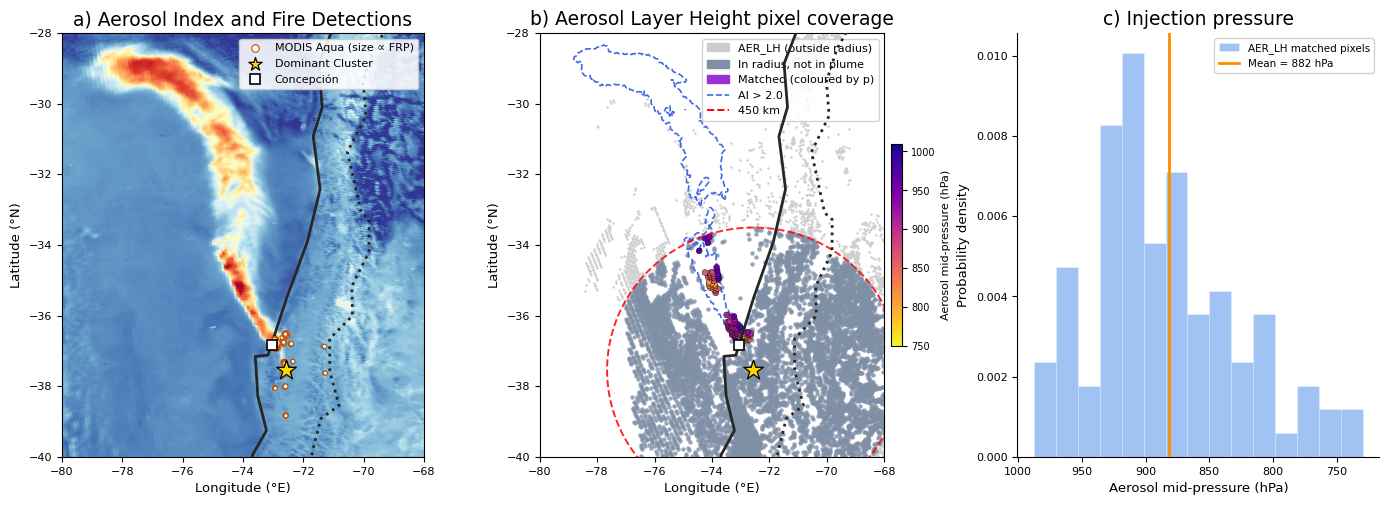


Saved: /Users/maperezc/Downloads/wildfires/outputs/figures/fig01b_mc_parameter_overview_1x3.png


In [22]:
def _draw_coastline_and_borders(ax, coast_color="0.15", border_color="0.15",
                                 coast_lw=2.0, border_lw=2.0, zorder=2):
    for geom in _land_geoms:
        if not geom.intersects(_domain_box):
            continue
        polys = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]
        for poly in polys:
            xc, yc = poly.exterior.xy
            ax.plot(xc, yc, color=coast_color, lw=coast_lw, zorder=zorder)
    for geom in _border_geoms:
        if not geom.intersects(_domain_box):
            continue
        lines = list(geom.geoms) if geom.geom_type == "MultiLineString" else [geom]
        for line in lines:
            xb, yb = line.xy
            ax.plot(xb, yb, color=border_color, lw=border_lw, ls=":", zorder=zorder)


# ── Alternative: 1×3 figure (no wind-aligned frame) ──────────────────────
CONC_LAT, CONC_LON = -36.8269, -73.0497

    
fig3, axes3 = plt.subplots(1, 3, figsize=(17.0, 5.5),
                             gridspec_kw={"wspace": 0.32})
ax3_a, ax3_b, ax3_c = axes3

# Concepción legend handle (shared by both map panels)
_conc_handle = Line2D([0], [0], marker="s", color="none", ms=7,
                       markerfacecolor="white", markeredgecolor="black",
                       markeredgewidth=1.2, label="Concepción")

# ━━ a) AER_AI and Fire Detections ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ax3_a.scatter(ai_data["lon"], ai_data["lat"], c=ai_vals,
               cmap="RdYlBu_r", vmin=-1, vmax=6, s=15.5,
               linewidths=0, rasterized=True, alpha=1.0, zorder=1)



_draw_coastline_and_borders(ax3_a)

frp_norm = modis_frp / modis_frp.max()
ax3_a.scatter(modis_lons, modis_lats, s=frp_norm * 60 + 8,
               c="white", edgecolors="#c05000", linewidths=0.8, zorder=5)
ax3_a.scatter(FIRE_LON, FIRE_LAT, **FIRE_KW)
ax3_a.plot(CONC_LON, CONC_LAT, "s", ms=7, mfc="white", mec="black", mew=1.2, zorder=9)

ax3_a.set_xlim(LON_MIN, LON_MAX);  ax3_a.set_ylim(LAT_MIN, LAT_MAX)
ax3_a.set_xlabel("Longitude (°E)", fontsize=9.5)
ax3_a.set_ylabel("Latitude (°N)", fontsize=9.5)
ax3_a.tick_params(labelsize=8)
ax3_a.legend(fontsize=8, loc="upper right", framealpha=0.88,
              handles=[
                  ax3_a.scatter([], [], s=30, c="white", edgecolors="#c05000",
                                lw=0.8, label="MODIS Aqua (size ∝ FRP)"),
                  ax3_a.scatter([], [], **FIRE_LEGEND_KW, label="Dominant Cluster"),
                  _conc_handle,
              ])
ax3_a.set_title("a) Aerosol Index and Fire Detections", fontsize=13.5)


# ━━ b) AER_LH pixel coverage ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
out_radius = ~in_radius
ax3_b.scatter(alh_lon[out_radius], alh_lat[out_radius],
               s=3, c="0.80", linewidths=0, rasterized=True, zorder=1)
ax3_b.scatter(alh_in_lon[~in_plume_mask], alh_in_lat[~in_plume_mask],
               s=10, c=COLOR_NOMATCH, linewidths=0, rasterized=True, zorder=2, alpha=0.8)
sc3_b = ax3_b.scatter(
    alh_in_lon[in_plume_mask], alh_in_lat[in_plume_mask],
    c=alh_in_pres[in_plume_mask], cmap="plasma_r", vmin=750, vmax=1010,
    s=18, linewidths=0.3, edgecolors="k", rasterized=True, zorder=4,
)

_draw_coastline_and_borders(ax3_b, zorder=6)

ax3_b.plot(FIRE_LON + (PRESS_RADIUS_KM / km_per_deg_lon) * np.cos(theta_c),
            FIRE_LAT + (PRESS_RADIUS_KM / km_per_deg_lat) * np.sin(theta_c),
            "r--", lw=1.4, alpha=0.85, zorder=5)
ax3_b.contour(LG, LaG, AI_Gr, levels=[AI_THRESHOLD],
               colors=["royalblue"], linewidths=[1.2], linestyles=["--"], zorder=3)
ax3_b.scatter(FIRE_LON, FIRE_LAT, **FIRE_KW)
ax3_b.plot(CONC_LON, CONC_LAT, "s", ms=7, mfc="white", mec="black", mew=1.2, zorder=9)

cb3_b = plt.colorbar(sc3_b, ax=ax3_b, fraction=0.028, pad=0.02)
cb3_b.set_label("Aerosol mid-pressure (hPa)", fontsize=8)
cb3_b.ax.tick_params(labelsize=7)
ax3_b.set_xlim(LON_MIN, LON_MAX);  ax3_b.set_ylim(LAT_MIN, LAT_MAX)
ax3_b.set_xlabel("Longitude (°E)", fontsize=9.5)
ax3_b.set_ylabel("Latitude (°N)", fontsize=9.5)
ax3_b.tick_params(labelsize=8)

_conc_handle_b = Line2D([0], [0], marker="s", color="none", ms=7,
                          markerfacecolor="white", markeredgecolor="black",
                          markeredgewidth=1.2, label="Concepción")
ax3_b.legend(fontsize=8, loc="upper right", framealpha=0.88,
              handles=[
                  mpatches.Patch(color="0.80", label="AER_LH (outside radius)"),
                  mpatches.Patch(color=COLOR_NOMATCH, label="In radius, not in plume"),
                  mpatches.Patch(color="#9b30d9", label="Matched (coloured by p)"),
                  #ax3_b.scatter([], [], **FIRE_LEGEND_KW, label="Dominant Cluster"),
                  Line2D([0], [0], color="royalblue", ls="--", lw=1.2, label=f"AI > {AI_THRESHOLD}"),
                  Line2D([0], [0], color="red", ls="--", lw=1.4, label=f"{PRESS_RADIUS_KM:.0f} km"),
                  #_conc_handle_b,
              ])
ax3_b.set_title(f"b) Aerosol Layer Height pixel coverage", fontsize=13.5)


# ━━ c) Injection-pressure KDE ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
n_bins  = max(15, int(np.sqrt(len(pres_hpa))))
ax3_c.hist(pres_hpa[pres_hpa>700], bins=n_bins, color=COLOR_KDE, alpha=0.45,
            edgecolor="white", linewidth=0.4, density=True, label="AER_LH matched pixels")
#kde_curve = pres_kde(p_plot)
#ax3_c.plot(p_plot, kde_curve, color=COLOR_KDE, lw=2.2, label="Fitted KDE")
#ax3_c.fill_between(p_plot, kde_curve, alpha=0.12, color=COLOR_KDE)
ax3_c.axvline(pres_mean, color=COLOR_MED, lw=2.0, zorder=6, label=f"Mean = {pres_mean:.0f} hPa")
ax3_c.invert_xaxis()
ax3_c.set_xlabel("Aerosol mid-pressure (hPa)", fontsize=9.5)
ax3_c.set_ylabel("Probability density", fontsize=9.5)
ax3_c.tick_params(labelsize=8)
ax3_c.spines[["top", "right"]].set_visible(False)
ax3_c.legend(fontsize=7.5, framealpha=0.88, loc="upper right")
ax3_c.set_title("c) Injection pressure", fontsize=13.5)


# ── Save ──────────────────────────────────────────────────────────────────
fig3_path = OUT_DIR / "fig01b_mc_parameter_overview_1x3.png"
fig3.savefig(fig3_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"\nSaved: {fig3_path}")